# Klasifikasi Penyakit Daun Jagung — MobileNetV2
### 4 Skenario Pengujian

Notebook ini menggunakan **1 arsitektur CNN (MobileNetV2)** dengan 4 skenario:
1. 80:20, tanpa augmentasi
2. 80:20, dengan augmentasi
3. 70:30, tanpa augmentasi
4. 70:30, dengan augmentasi

Metrik: **Accuracy, Precision, Recall, F1-Score, dan Confusion Matrix**.

> Dataset dapat diambil dari Kaggle. Pada Google Colab, upload/unduh dataset terlebih dahulu lalu arahkan `DATASET_DIR` ke folder dataset.


In [2]:
# 1. Instalasi library Kaggle
!pip -q install kagglehub seaborn scikit-learn


In [3]:
# 2. Import library
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Download dataset langsung dari Kaggle

Notebook ini akan mengunduh dataset secara otomatis menggunakan KaggleHub.

**Penting:** link yang kamu kirim adalah link Kaggle Notebook, bukan slug dataset.
Slug dataset yang dipakai di bawah adalah dataset penyakit daun jagung yang sesuai.


In [4]:
# 3. Download dataset Kaggle otomatis
import kagglehub

KAGGLE_DATASET = "smaranjitghose/corn-or-maize-leaf-disease-dataset"

print("Mengunduh:", KAGGLE_DATASET)
downloaded_path = kagglehub.dataset_download(KAGGLE_DATASET)

print("Lokasi download:", downloaded_path)

# Mencari folder yang berisi subfolder kelas
def find_dataset_root(base_path):
    candidates = [base_path]

    for root, dirs, files in os.walk(base_path):
        if len(dirs) >= 2:
            candidates.append(root)

    candidates = sorted(
        set(candidates),
        key=lambda x: x.count(os.sep),
        reverse=True
    )

    for path in candidates:
        subdirs = [
            d for d in os.listdir(path)
            if os.path.isdir(os.path.join(path, d))
        ]
        if len(subdirs) >= 2:
            return path

    return base_path

DATASET_DIR = find_dataset_root(downloaded_path)

print("DATASET_DIR =", DATASET_DIR)
print("Isi:", os.listdir(DATASET_DIR)[:20])


Mengunduh: smaranjitghose/corn-or-maize-leaf-disease-dataset


100%|██████████| 161M/161M [00:01<00:00, 116MB/s]

Extracting files...


Lokasi download: /root/.cache/kagglehub/datasets/smaranjitghose/corn-or-maize-leaf-disease-dataset/versions/1
DATASET_DIR = /root/.cache/kagglehub/datasets/smaranjitghose/corn-or-maize-leaf-disease-dataset/versions/1/data
Isi: ['Healthy', 'Blight', 'Gray_Leaf_Spot', 'Common_Rust']


In [5]:
# 4. Membuat daftar seluruh gambar
# Menentukan nama kelas dari folder dataset
class_names = sorted([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
])

print("Kelas:", class_names)
print("Jumlah kelas:", len(class_names))
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

paths, labels = [], []

for label, class_name in enumerate(class_names):
    class_dir = os.path.join(DATASET_DIR, class_name)
    for root, _, files in os.walk(class_dir):
        for f in files:
            if f.lower().endswith(VALID_EXT):
                paths.append(os.path.join(root, f))
                labels.append(label)

df = pd.DataFrame({"path": paths, "label": labels})
df["class"] = df["label"].map(dict(enumerate(class_names)))

print("Total gambar:", len(df))
display(df["class"].value_counts().sort_index())


Kelas: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
Jumlah kelas: 4
Total gambar: 4188


,count
class,
Blight,1146
Common_Rust,1306
Gray_Leaf_Spot,574
Healthy,1162


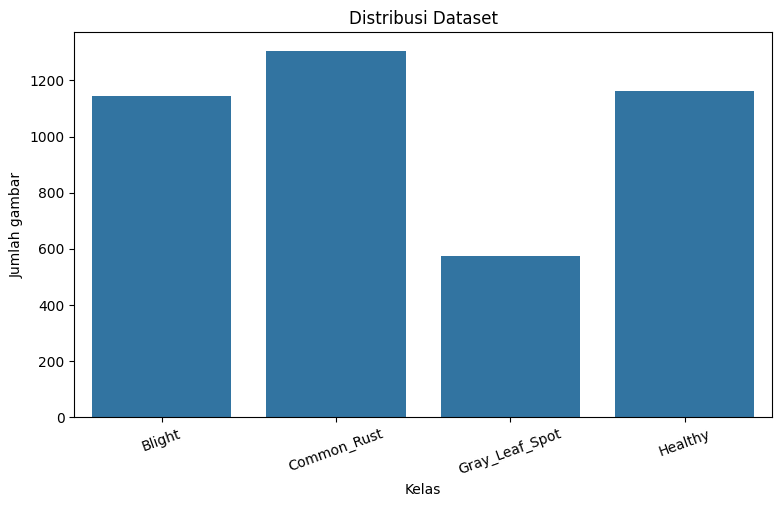

In [6]:
# 5. Visualisasi distribusi kelas
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="class")
plt.title("Distribusi Dataset")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=20)
plt.show()


## 4. Fungsi untuk membuat train/test split

Split dilakukan **secara stratified** agar proporsi kelas tetap terjaga.


In [7]:
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15

def make_split(test_size):
    train_df, test_df = train_test_split(
        df,
        test_size=test_size,
        random_state=SEED,
        stratify=df["label"]
    )
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

def make_datasets(train_df, test_df, augment=False):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        labels="inferred",
        label_mode="int",
        class_names=class_names,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED,
        validation_split=None
    )

    # Gunakan file path hasil split secara eksplisit agar skenario split benar-benar diterapkan.
    def df_to_ds(dataframe, shuffle):
        ds = tf.data.Dataset.from_tensor_slices(
            (dataframe["path"].values, dataframe["label"].values)
        )
        if shuffle:
            ds = ds.shuffle(len(dataframe), seed=SEED)

        def load_img(path, label):
            img = tf.io.read_file(path)
            img = tf.image.decode_image(img, channels=3, expand_animations=False)
            img.set_shape([None, None, 3])
            img = tf.image.resize(img, IMG_SIZE)
            img = tf.cast(img, tf.float32)
            return img, label

        ds = ds.map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
        return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    train_ds = df_to_ds(train_df, True)
    test_ds = df_to_ds(test_df, False)

    if augment:
        augmentation = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.15),
            layers.RandomZoom(0.15),
            layers.RandomContrast(0.10),
        ], name="augmentation")

        train_ds = train_ds.map(
            lambda x, y: (augmentation(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        ).prefetch(tf.data.AUTOTUNE)

    return train_ds, test_ds


## 5. Model MobileNetV2

Satu arsitektur digunakan untuk semua skenario agar perbedaan hasil berasal dari **skenario pengujian**, bukan pergantian arsitektur.


In [8]:
def build_model(num_classes):
    base = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1./127.5, offset=-1)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [9]:
def run_experiment(name, test_size, augment):
    print("\n" + "="*70)
    print(name)
    print("="*70)

    train_df, test_df = make_split(test_size)

    print(f"Train : {len(train_df)} gambar")
    print(f"Test  : {len(test_df)} gambar")
    print(f"Augmentasi: {augment}")

    train_ds, test_ds = make_datasets(train_df, test_df, augment)

    model = build_model(len(class_names))

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-6
        )
    ]

    # Dari train set, sisihkan 10% untuk validasi.
    val_count = max(1, int(len(train_df) * 0.10))
    train_count = len(train_df) - val_count

    # Recreate split menjadi train/validation/test.
    train_part, val_part = train_test_split(
        train_df,
        test_size=0.10,
        random_state=SEED,
        stratify=train_df["label"]
    )

    train_ds, val_ds = make_datasets(train_part, val_part, augment)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    metrics = {
        "Skenario": name,
        "Train": f"{len(train_part)} ({len(train_part)/len(df)*100:.1f}%)",
        "Test": f"{len(test_df)} ({len(test_df)/len(df)*100:.1f}%)",
        "Augmentasi": "Ya" if augment else "Tidak",
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # Grafik training
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"Accuracy Training — {name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    return model, history, metrics


# 6. Menjalankan 4 skenario

**Skenario 1:** 80:20 tanpa augmentasi  
**Skenario 2:** 80:20 dengan augmentasi  
**Skenario 3:** 70:30 tanpa augmentasi  
**Skenario 4:** 70:30 dengan augmentasi



Skenario 1 — 80:20 Tanpa Augmentasi
Train : 3350 gambar
Test  : 838 gambar
Augmentasi: False
Found 4188 files belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Found 4188 files belonging to 4 classes.
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 54s 359ms/step - accuracy: 0.7778 - loss: 0.5633 - val_accuracy: 0.9164 - val_loss: 0.2310 - learning_rate: 0.0010
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.9068 - loss: 0.2524 - val_accuracy: 0.9343 - val_loss: 0.1891 - learning_rate: 0.0010
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9197 - loss: 0.2142 - val_accuracy: 0.9433 - val_loss: 0.1743 - learning_rate: 0.0010
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.9290 - loss: 0.1914 - val_accuracy: 0.9373 - val_loss: 0.1660 - learning_rate: 0.0010
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9310 - loss: 0.1729 - val_accuracy: 0.9343 - val_loss: 0.1617 - learning_rate: 0.0010
Epoch 6/15
95/95 ━

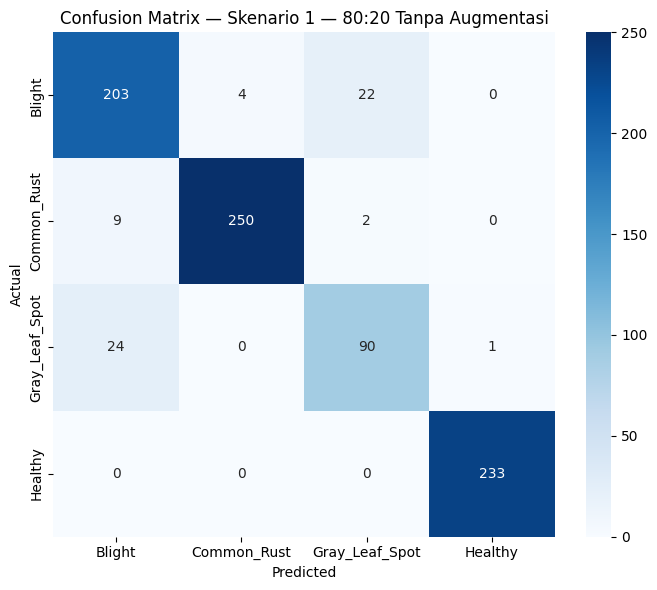

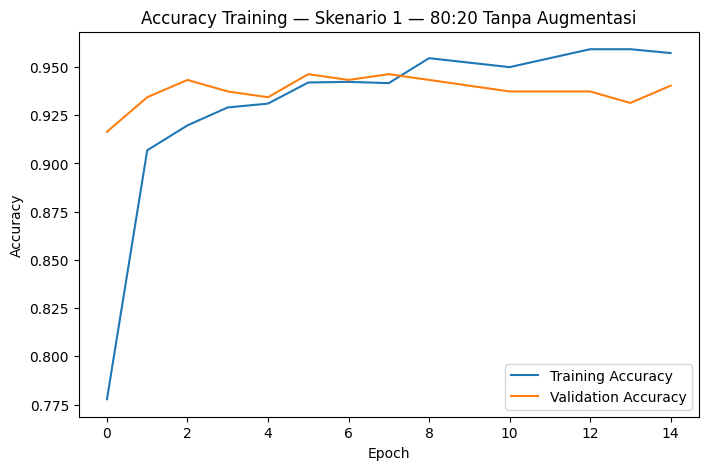


Skenario 2 — 80:20 Dengan Augmentasi
Train : 3350 gambar
Test  : 838 gambar
Augmentasi: True
Found 4188 files belonging to 4 classes.
Found 4188 files belonging to 4 classes.
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 55s 488ms/step - accuracy: 0.7993 - loss: 0.5297 - val_accuracy: 0.9104 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 33s 340ms/step - accuracy: 0.8952 - loss: 0.2862 - val_accuracy: 0.9373 - val_loss: 0.1942 - learning_rate: 0.0010
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 34s 353ms/step - accuracy: 0.9015 - loss: 0.2513 - val_accuracy: 0.9433 - val_loss: 0.1721 - learning_rate: 0.0010
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 353ms/step - accuracy: 0.9085 - loss: 0.2425 - val_accuracy: 0.9433 - val_loss: 0.1600 - learning_rate: 0.0010
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 33s 343ms/step - accuracy: 0.9035 - loss: 0.2266 - val_accuracy: 0.9433 - val_loss: 0.1636 - learning_rate: 0.0010
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 42s 352ms/step - accu

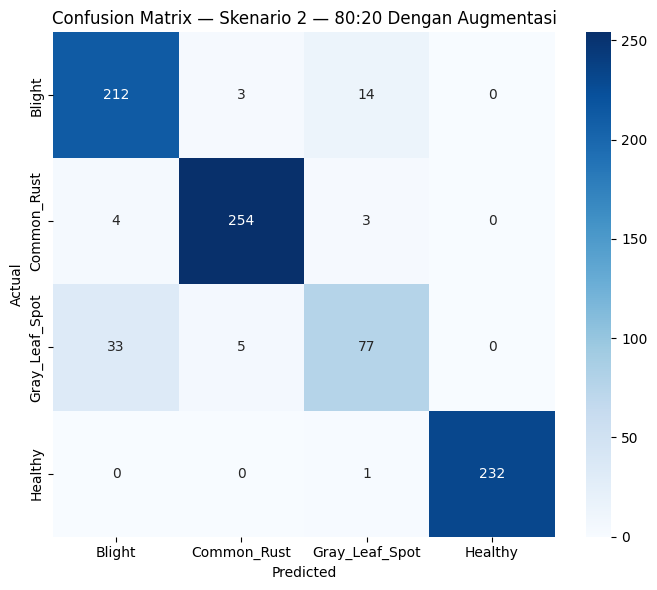

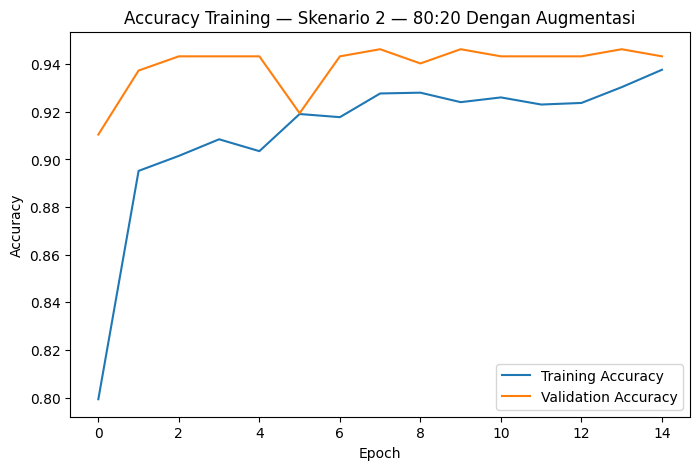


Skenario 3 — 70:30 Tanpa Augmentasi
Train : 2931 gambar
Test  : 1257 gambar
Augmentasi: False
Found 4188 files belonging to 4 classes.
Found 4188 files belonging to 4 classes.
Epoch 1/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 33s 297ms/step - accuracy: 0.7929 - loss: 0.5378 - val_accuracy: 0.8946 - val_loss: 0.2905 - learning_rate: 0.0010
Epoch 2/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.8984 - loss: 0.2580 - val_accuracy: 0.9116 - val_loss: 0.2371 - learning_rate: 0.0010
Epoch 3/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.9132 - loss: 0.2186 - val_accuracy: 0.9218 - val_loss: 0.2145 - learning_rate: 0.0010
Epoch 4/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9245 - loss: 0.1882 - val_accuracy: 0.9286 - val_loss: 0.2077 - learning_rate: 0.0010
Epoch 5/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9363 - loss: 0.1691 - val_accuracy: 0.9388 - val_loss: 0.1959 - learning_rate: 0.0010
Epoch 6/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9

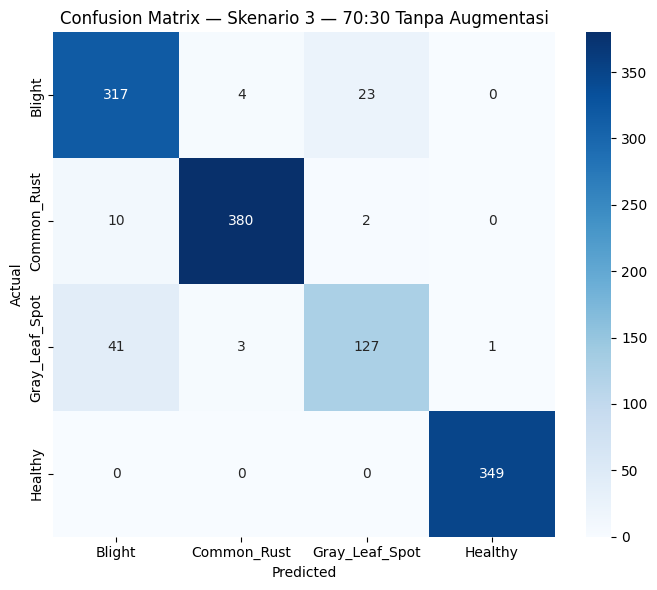

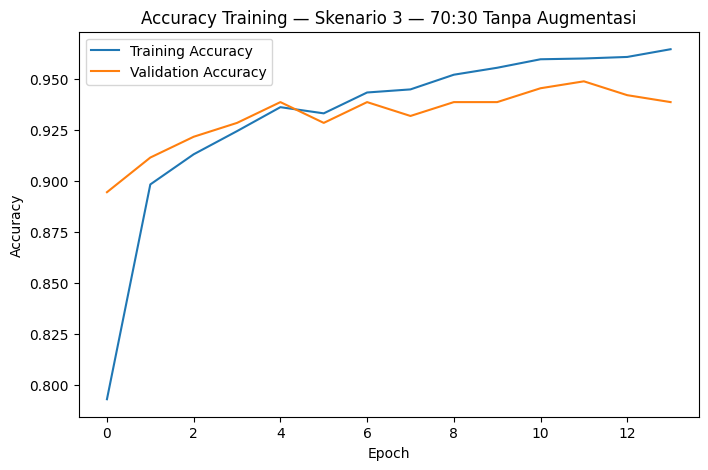


Skenario 4 — 70:30 Dengan Augmentasi
Train : 2931 gambar
Test  : 1257 gambar
Augmentasi: True
Found 4188 files belonging to 4 classes.
Found 4188 files belonging to 4 classes.
Epoch 1/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 49s 481ms/step - accuracy: 0.8017 - loss: 0.5147 - val_accuracy: 0.9184 - val_loss: 0.2671 - learning_rate: 0.0010
Epoch 2/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 29s 343ms/step - accuracy: 0.8832 - loss: 0.2922 - val_accuracy: 0.9218 - val_loss: 0.2341 - learning_rate: 0.0010
Epoch 3/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 43s 367ms/step - accuracy: 0.9037 - loss: 0.2442 - val_accuracy: 0.9150 - val_loss: 0.2292 - learning_rate: 0.0010
Epoch 4/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 28s 339ms/step - accuracy: 0.9094 - loss: 0.2364 - val_accuracy: 0.9150 - val_loss: 0.2171 - learning_rate: 0.0010
Epoch 5/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 28s 339ms/step - accuracy: 0.9177 - loss: 0.2089 - val_accuracy: 0.9252 - val_loss: 0.2189 - learning_rate: 0.0010
Epoch 6/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 29s 339ms/step - acc

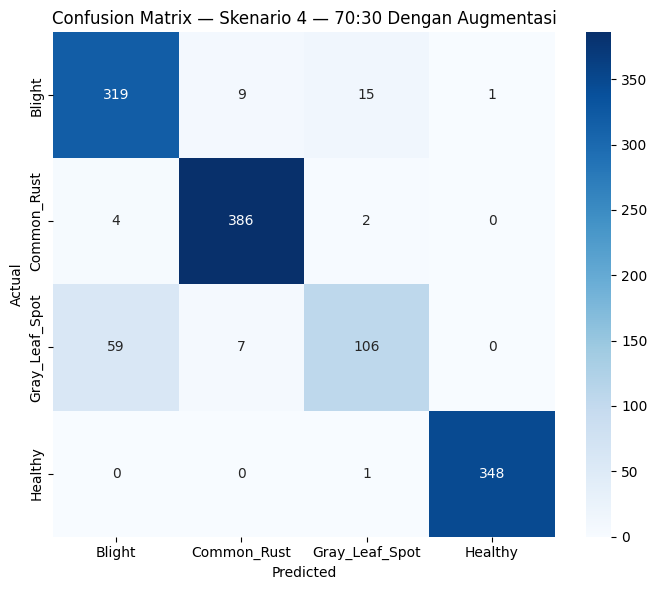

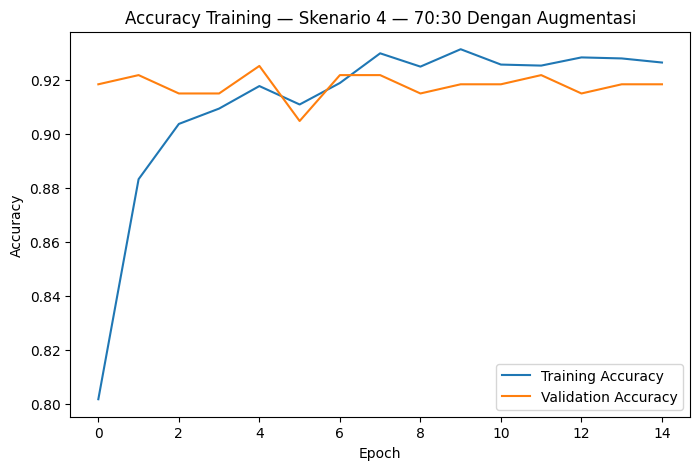

In [10]:
results = []
models_saved = {}

scenarios = [
    ("Skenario 1 — 80:20 Tanpa Augmentasi", 0.20, False),
    ("Skenario 2 — 80:20 Dengan Augmentasi", 0.20, True),
    ("Skenario 3 — 70:30 Tanpa Augmentasi", 0.30, False),
    ("Skenario 4 — 70:30 Dengan Augmentasi", 0.30, True),
]

for name, test_size, augment in scenarios:
    model, history, metrics = run_experiment(name, test_size, augment)
    results.append(metrics)
    models_saved[name] = model


In [11]:
# 7. Tabel perbandingan hasil
results_df = pd.DataFrame(results)

metric_cols = ["Accuracy", "Precision", "Recall", "F1-Score"]
results_display = results_df.copy()

for col in metric_cols:
    results_display[col] = (results_display[col] * 100).round(2).astype(str) + "%"

display(results_display)


,Skenario,Train,Test,Augmentasi,Accuracy,Precision,Recall,F1-Score
0,Skenario 1 — 80:20 Tanpa Augmentasi,3015 (72.0%),838 (20.0%),Tidak,92.6%,92.68%,92.6%,92.63%
1,Skenario 2 — 80:20 Dengan Augmentasi,3015 (72.0%),838 (20.0%),Ya,92.48%,92.39%,92.48%,92.3%
2,Skenario 3 — 70:30 Tanpa Augmentasi,2637 (63.0%),1257 (30.0%),Tidak,93.32%,93.31%,93.32%,93.25%
3,Skenario 4 — 70:30 Dengan Augmentasi,2637 (63.0%),1257 (30.0%),Ya,92.2%,92.18%,92.2%,91.86%


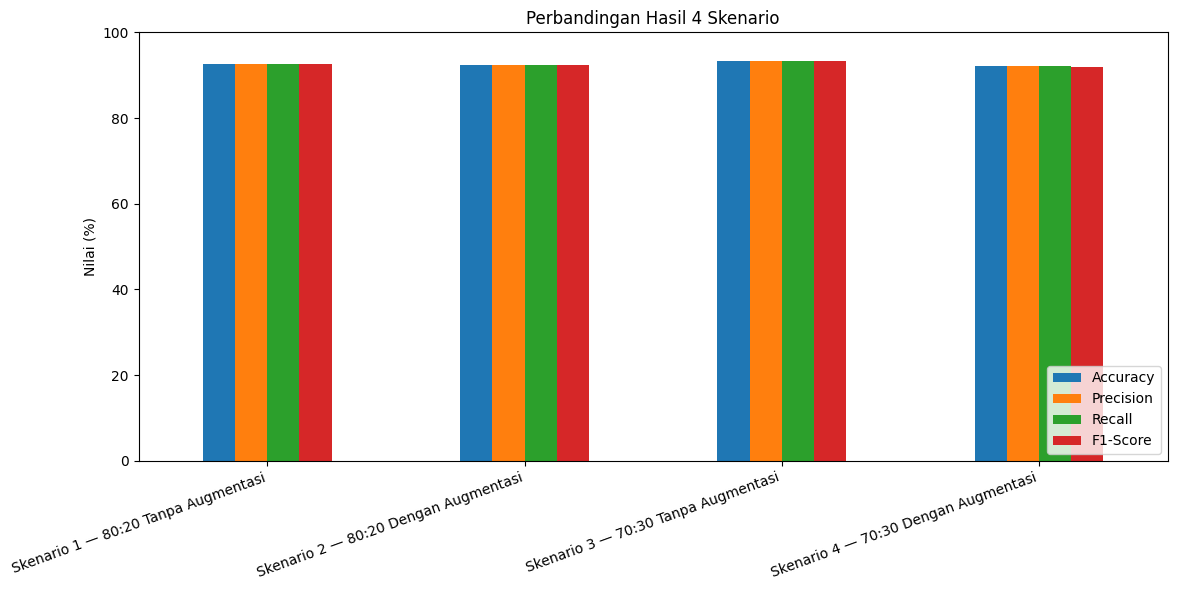

In [12]:
# 8. Grafik perbandingan metrik
plot_df = results_df.set_index("Skenario")[metric_cols] * 100

ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("Nilai (%)")
ax.set_xlabel("")
ax.set_title("Perbandingan Hasil 4 Skenario")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [13]:
# 9. Simpan hasil ke CSV
results_df.to_csv("/content/hasil_4_skenario.csv", index=False)
print("Tersimpan: /content/hasil_4_skenario.csv")


Tersimpan: /content/hasil_4_skenario.csv


## 10. Kesimpulan

Isi kesimpulan berdasarkan **hasil eksperimen yang benar-benar diperoleh**, misalnya:

> Pengujian dilakukan menggunakan satu arsitektur CNN, yaitu MobileNetV2, dengan empat skenario pengujian. Setiap skenario dibandingkan berdasarkan Accuracy, Precision, Recall, F1-Score, dan Confusion Matrix. Perbedaan hasil digunakan untuk melihat pengaruh pembagian data dan augmentasi terhadap performa klasifikasi penyakit daun jagung.

Jangan menentukan skenario terbaik sebelum melihat hasil aktual pada tabel.
